In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from astropy.table import Table
from gliders.utils import sigma_clipping, grow_mask, get_profile_from_border, normalize_data
from gliders.artifacts import detect_artifacts, get_artifact_flag, clean_artifacts, detect_and_clean_artifacts
from gliders.background_suppressor import suppress_background, show_all_methods
from scipy.stats import norm
from scipy.signal import convolve2d
from astropy.convolution import Gaussian2DKernel
import warnings
from astropy.utils.exceptions import AstropyDeprecationWarning
from photutils.utils.exceptions import NoDetectionsWarning
warnings.simplefilter('ignore', category=AstropyDeprecationWarning)
warnings.simplefilter('ignore', category=NoDetectionsWarning)

def extract_band_data(hdu_list, verbose=True, bands_to_analyze = ['r']):
    all_bands = {}
    all_img_diffs = {}
    all_img_areas = {}
    all_weights = {}
    all_wgh_diffs = {}
    all_wgh_areas = {}
    ref_hdu = None
    for hdu in hdu_list:
        try:
            header = hdu._header
            if verbose:
                print(header)
            band = header.get("BAND")
            if band not in bands_to_analyze: continue
            image_type = header.get("IMAGETYP")
            imagew = header.get("IMAGEW")
            imageh = header.get("IMAGEH")

            if band is None or image_type is None or imagew is None or imageh is None:
                continue  # Skip if essential header info is missing

            img_dim_diff = abs(imagew - imageh)
            img_area = imagew * imageh

            if image_type == "image":
                if band not in all_bands or img_area > all_img_areas[band] or (img_area == all_img_areas[band] and img_dim_diff < all_img_diffs[band]):
                    all_bands[band] = hdu.copy().data
                    all_img_areas[band] = img_area
                    all_img_diffs[band] = img_dim_diff
                    ref_hdu = hdu.header

            elif image_type == "invvar":
                w_map = hdu.copy().data
                w_map[w_map == 0] += 1  # Avoid division by zero
                weight = 1 / np.sqrt(w_map)
                if band not in all_weights or img_area > all_wgh_areas[band] or (img_area == all_wgh_areas[band] and img_dim_diff < all_wgh_diffs[band]):
                    all_weights[band] = weight
                    all_wgh_areas[band] = img_area
                    all_wgh_diffs[band] = img_dim_diff

        except Exception as e:
            print(f"Skipped HDU due to error: {e}")

    return all_bands, all_weights, ref_hdu

file_dir = "C:/Astrostuff/PhD/Data/DESI FITS/"
artif_file = "D:/Astrostuff/PhD/Data/My_data/DESI_New_mergers.csv"
artif_catalog = Table.read(artif_file, format = "csv", converters = {"object_id":str})
print(len(artif_catalog))
print(artif_catalog)

3754
    object_id         ra      dec       z    ...    I    merger_predicted  ES
----------------- --------- -------- ------- ... ------- ---------------- ---
39627902957912363 211.09828  4.71795 0.02977 ... 0.41312                1   1
39632991730798910 253.11914 35.41754 0.05766 ...  0.2024                1   1
39627829528234714 150.37899  1.68886 0.09869 ... 0.01352                1   1
39627830664894213  218.2308  1.86938 0.02998 ... 0.58443                1   1
39633427988745611 271.28566 63.42304  0.0915 ...  0.2459                1   1
39627758090851335  212.4838 -1.23884  0.0248 ... 0.47045                1   1
39633104083616306 152.75604 41.58966 0.05861 ... 0.60419                1   1
39627877821449269 150.00236  3.67734 0.07391 ... 0.03693                1   1
39627773882401920   73.5449 -0.39993 0.05467 ... 0.15411                1   1
39633321931571417 185.66454 55.08292 0.03664 ... 0.28208                1   1
              ...       ...      ...     ... ...     ...   

0 39627817436057197
1 39633293271894039
2 39627770304661746
3 39628427904418064
4 39633293347391690
5 39627811408841508
6 39627890869931123
7 39628427887641099
8 39633393155049991
9 39633345725857934
10 39633127575915118
11 39627740038567631
12 39633448838627552
13 39627788356946460
14 39627859706253037
15 39628417167002618
16 39633325270240671
17 39627770162055725
18 39627793096507752
19 39633314805449666
20 39627776323489891


C:\Users\Alejandro\AppData\Local\Temp\ipykernel_3152\4199513248.py:67: UserWarning: No configuration object was provided. Will use default configuration.
  deb_res = deblend_and_mask_sources(image, image_convolved, seg_map = seg_map, source_pos = source_pos, config = None, use_redshift = False,


Redshift-based deblending is not activated
Detected 48 sources after de-blending.


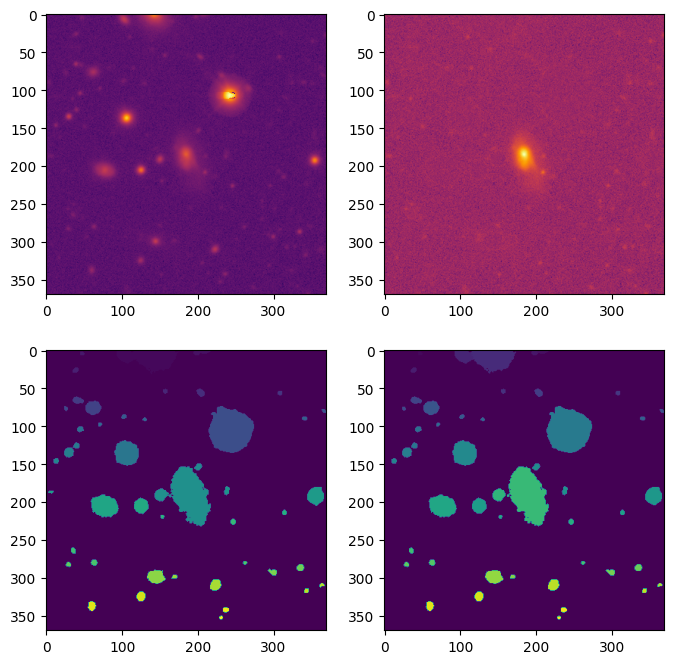

21 39627853691618718
Redshift-based deblending is not activated


C:\Users\Alejandro\AppData\Local\Temp\ipykernel_3152\4199513248.py:67: UserWarning: No configuration object was provided. Will use default configuration.
  deb_res = deblend_and_mask_sources(image, image_convolved, seg_map = seg_map, source_pos = source_pos, config = None, use_redshift = False,


Detected 27 sources after de-blending.


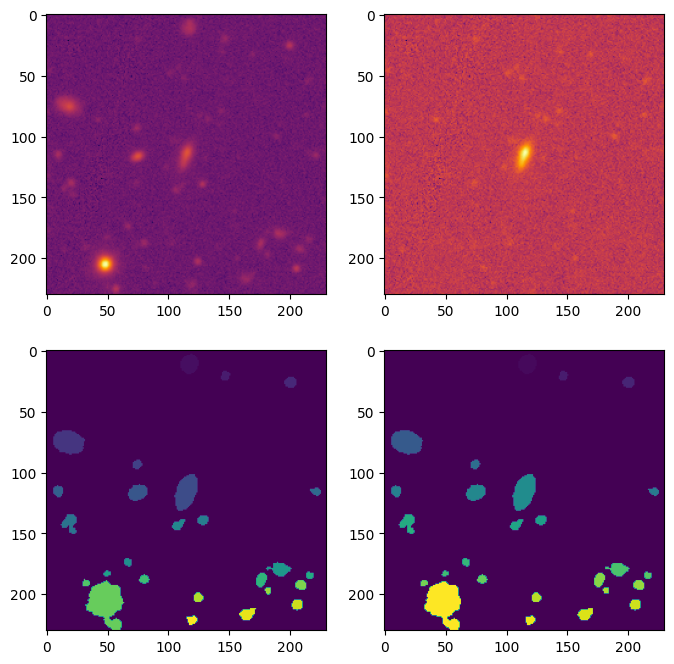

22 39633132130926811
Redshift-based deblending is not activated


C:\Users\Alejandro\AppData\Local\Temp\ipykernel_3152\4199513248.py:67: UserWarning: No configuration object was provided. Will use default configuration.
  deb_res = deblend_and_mask_sources(image, image_convolved, seg_map = seg_map, source_pos = source_pos, config = None, use_redshift = False,


Detected 6 sources after de-blending.


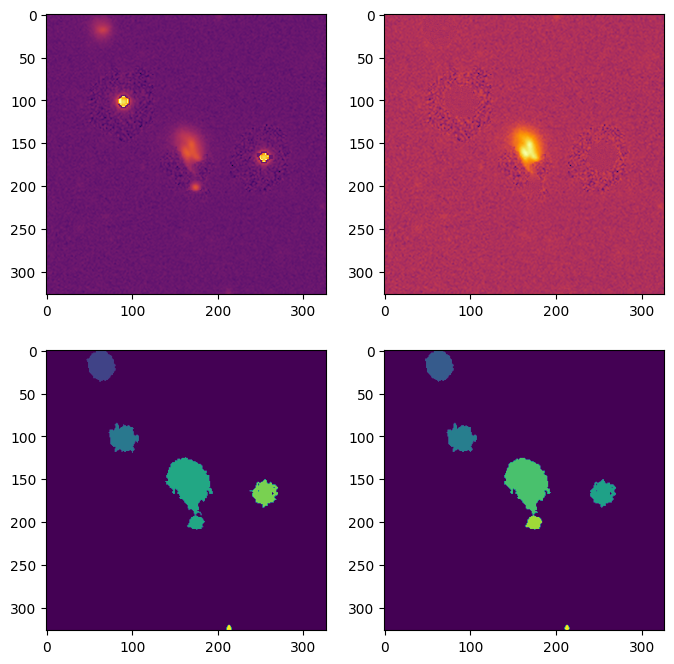

23 39633134743983521


C:\Users\Alejandro\AppData\Local\Temp\ipykernel_3152\4199513248.py:67: UserWarning: No configuration object was provided. Will use default configuration.
  deb_res = deblend_and_mask_sources(image, image_convolved, seg_map = seg_map, source_pos = source_pos, config = None, use_redshift = False,


Redshift-based deblending is not activated
Detected 12 sources after de-blending.


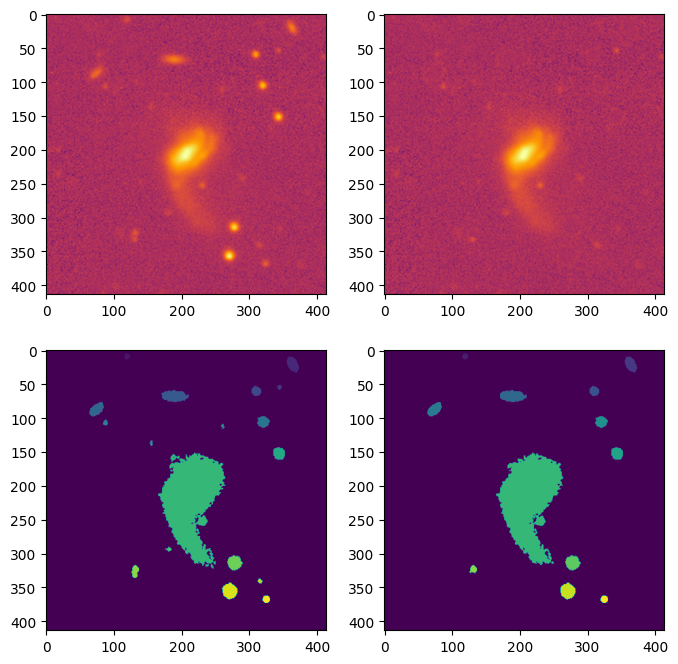

24 39627670597668378
25 39632971891740405
26 39627740084700433


C:\Users\Alejandro\AppData\Local\Temp\ipykernel_3152\4199513248.py:67: UserWarning: No configuration object was provided. Will use default configuration.
  deb_res = deblend_and_mask_sources(image, image_convolved, seg_map = seg_map, source_pos = source_pos, config = None, use_redshift = False,


Redshift-based deblending is not activated
Detected 25 sources after de-blending.


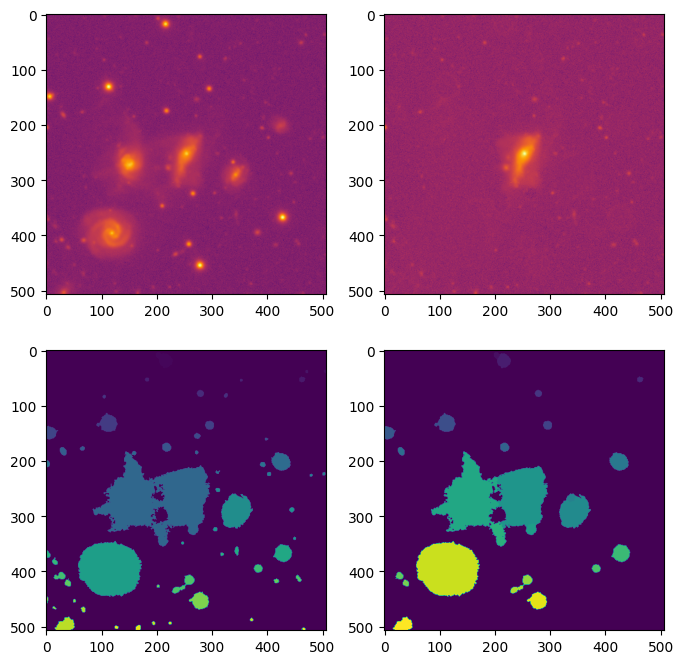

27 39633311299013536
28 39627817436057123
29 39627812461615126


C:\Users\Alejandro\AppData\Local\Temp\ipykernel_3152\4199513248.py:67: UserWarning: No configuration object was provided. Will use default configuration.
  deb_res = deblend_and_mask_sources(image, image_convolved, seg_map = seg_map, source_pos = source_pos, config = None, use_redshift = False,


Redshift-based deblending is not activated
Detected 53 sources after de-blending.


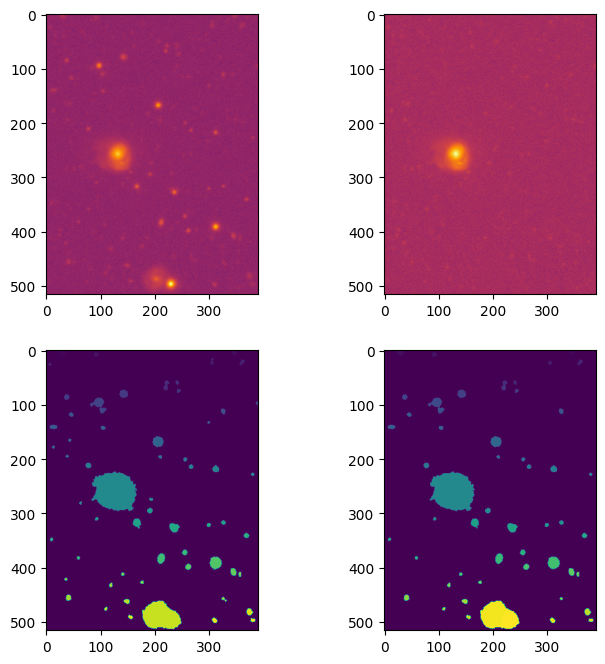

30 39633422527758917


C:\Users\Alejandro\AppData\Local\Temp\ipykernel_3152\4199513248.py:67: UserWarning: No configuration object was provided. Will use default configuration.
  deb_res = deblend_and_mask_sources(image, image_convolved, seg_map = seg_map, source_pos = source_pos, config = None, use_redshift = False,


Redshift-based deblending is not activated
Detected 44 sources after de-blending.


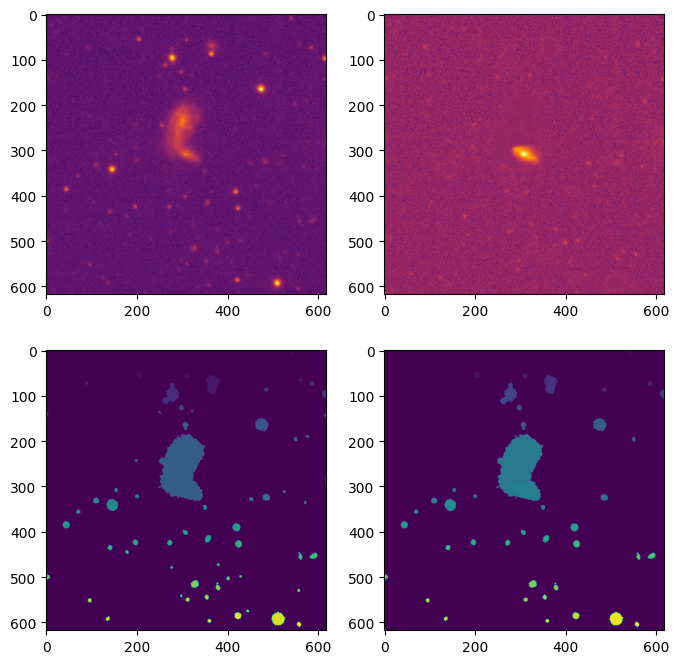

DONE!


In [2]:
bleed_radii = []
areas = []
from gliders.cleaning_configs import configs
config = configs["default"]
for ii, object_info in enumerate(artif_catalog[140:]):
    object_id = object_info[0]
    print(ii, object_id)
    obj_coords = (object_info[1],object_info[2])
    redshift = object_info[3]
    bands = ['r'] #,'g']
    file_name = f"{object_id}_{"".join(bands)}.fits"
    sources_name = f"{object_id}_sources.fits"

    file_path = os.path.join(file_dir, file_name)
    sources_path = os.path.join(file_dir, sources_name)
    try:
        with fits.open(file_path) as hdu_list:
            # hdu_list.info()
            all_bands, all_weights, ref_header = extract_band_data(hdu_list, verbose=False, bands_to_analyze=bands)
    except:
        continue

    with fits.open(sources_path) as hdul:
        data = hdul[1].data
        as_table = Table(data)
    wcs = WCS(ref_header)
    tractor_x_pix, tractor_y_pix = wcs.all_world2pix(as_table['ra'], as_table['dec'], 0)  # origin=0 for Python indexing
    source_x_pix, source_y_pix = wcs.all_world2pix(obj_coords[0], obj_coords[1], 0)  # origin=0 for Python indexing
    source_pos = (np.round(source_x_pix), np.round(source_y_pix))
    as_table['x_centroid'] = tractor_x_pix
    as_table['y_centroid'] = tractor_y_pix
    phot_sources = as_table['type','x_centroid','y_centroid']
    image = all_bands['r']


    if obj_coords[1] > 32.375:
        pix_scale = 1.72
    else:
        pix_scale = 1

    # from gliders.stars import detect_and_mask_stars
    from photutils.segmentation import SourceCatalog, detect_threshold, detect_sources
    # from gliders.background_suppressor import suppress_background
    source_min_pix = 10
    # image = suppress_background(image, method = "layers")

    from gliders.deblending import deblend_and_mask_sources, get_deblended_map, analyze_deblended_map, remove_deblended_objects
    from gliders.utils import get_main_source_label, get_z_sources_in_image
    from gliders.pipeline import update_detections
    from gliders.artifacts import detect_and_clean_artifacts


    if ii < 18:
        continue

    img_bck_lvl, img_bck_std = sigma_clipping(image)

    # image, _, _ = detect_and_clean_artifacts(image, config, img_bck_lvl)
    image_convolved, seg_map, main_source_segment = update_detections(image, config=config, source_min_pix = 20, use_filter=True)


    wcs = WCS(ref_header)
    # print(config.galaxy_detection_threshold)
    #


    deb_res = deblend_and_mask_sources(image, image_convolved, seg_map = seg_map, source_pos = source_pos, config = None, use_redshift = False,
                                       ref_redshift = redshift, max_delta_z = 0.005, z_sources = None, query_z_sources = True, wcs = wcs, z_query_timeout = 10, z_query_synch = True, use_photo_type = True, phot_sources = phot_sources, keep_undecided_segments = False, pix_scale=1, show_plots=False, verbose=True)

    image_deblended, deb_seg_map, deblending_mask, deblended_flag, failed_z_query = deb_res

    # seg_map_deb_raw = get_deblended_map(image_convolved, seg_map, deblend_tool = 'sep', npixels = 50, contrast = 0.005, levels = 32,
    #                   deblend_mode = None, connect_mode = None, detection_threshold = 5, verbose = False)
    #
    #
    # #
    # #
    # # seg_map_deb_raw = seg_map
    # z_sources=None
    # deb_cat = SourceCatalog(image, seg_map_deb_raw)
    # deb_cat_tab = deb_cat.to_table()
    # deb_main_label = get_main_source_label(seg_map_deb_raw, source_pos=source_pos, table=deb_cat_tab)
    # safe_label_list, discard_label_list = None, None
    #
    # # z_sources, failed_z_query = get_z_sources_in_image(seg_map_deb_raw, wcs, 5, True, z_query_attempts=1)
    #
    # seg_map_deb_analyzed = analyze_deblended_map(seg_map_deb_raw, deb_main_label, use_redshift = True, redshift = redshift, max_delta_z = 0.01,
    #                       z_sources = z_sources, use_photo_type = True, phot_sources = phot_sources, keep_undecided_labels = True,
    #                       show_plots = False, verbose = False)
    #
    # image_deblended = remove_deblended_objects(image, seg_map_deb_analyzed, deb_main_label, pix_scale=pix_scale,mask_radius_factor=1)
    #
    fig, ax = plt.subplots(2,2, figsize = (8,8))
    ax[0,0].imshow(image-image.min(), norm = "log", cmap = "inferno")
    ax[0,1].imshow(image_deblended-image_deblended.min(), norm = "log", cmap = "inferno")
    ax[1,0].imshow(seg_map.data)
    ax[1,1].imshow(deb_seg_map.data)
    plt.show()


    # segment_slack = 15
    # for segment in seg_map.segments:
    #     segment_mask = segment.data.astype(bool)
    #     pad_top = min(segment_slack, segment.bbox.iymin)
    #     pad_bottom = min(segment_slack, image.shape[0] - segment.bbox.iymax)
    #     pad_left = min(segment_slack, segment.bbox.ixmin)
    #     pad_right = min(segment_slack, image.shape[1] - segment.bbox.ixmax)
    #     segment_mask_padded = np.pad(segment_mask, ((pad_top, pad_bottom), (pad_left, pad_right)),
    #                              mode="constant", constant_values=False)
    #
    #     segment_cutout = image[max(0, segment.bbox.iymin - segment_slack):min(image.shape[0], segment.bbox.iymax + segment_slack),
    #                      max(0, segment.bbox.ixmin - segment_slack):min(image.shape[1], segment.bbox.ixmax + segment_slack)]
    #
    #     mean_profile = np.array(get_profile_from_border(segment_cutout, segment_mask_padded, segment_slack))
    #     x_pts = range(len(mean_profile))
    #     lvl_mask = mean_profile < (img_bck_lvl + img_bck_std)
    #     if lvl_mask.any():
    #         lvl_intercept = np.array(x_pts)[lvl_mask][0]
    #     else:
    #         continue
    #     bleed_radii.append(lvl_intercept)
    #     areas.append(segment.area)



    # break
    # deb_image = deblend_and_mask_sources(image, main_source_segment = main_source_segment, ref_redshift = redshift, use_redshift=True, wcs=wcs, use_photo_type = False, phot_sources = phot_sources, show_plots=True, verbose=True)
    # plt.imshow(image - image.min(), norm = "log")
    # plt.show()
    if ii >= 30:
        break
# bleed_radii = np.array(bleed_radii)
# areas = np.array(areas)
print("DONE!")

12897 12897
3
1796
7918
2045
587
254
120
54
28
30
11
17
20
4
6
4
- lin:
y = 0.7419 + 0.0066*lin(x) -> R^2 = 0.9858

- sqrt:
y = -2.9278 + 0.3565*sqrt(x) -> R^2 = 0.9641



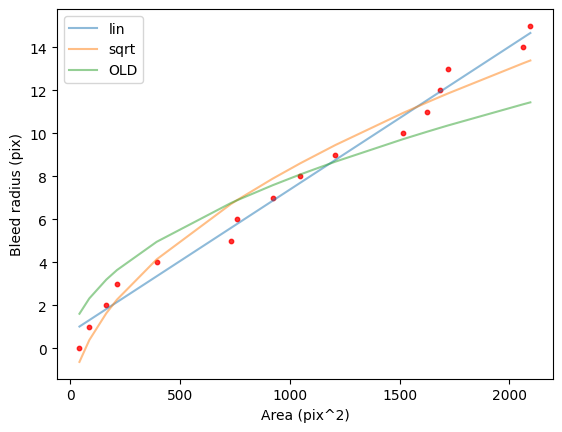

In [50]:
from scipy.stats import linregress

xtremes = areas > 10000
areas_f = areas[~xtremes]
bleed_radii_f = bleed_radii[~xtremes]
print(len(areas_f), len(bleed_radii_f))
bleed_radii_lvls = np.unique(bleed_radii_f)
mean_areas = []
mean_areas_std = []
mean_areas_n = []
for bleed_lvl in bleed_radii_lvls:
    select_mask = bleed_radii_f == bleed_lvl
    print(len(areas_f[select_mask]))
    # mean_area, area_std = sigma_clipping(areas_f[select_mask])
    mean_area = areas_f[select_mask].mean()
    area_std = np.std(areas_f[select_mask])
    mean_areas.append(mean_area)
    mean_areas_std.append(area_std)
    mean_areas_n.append(len(areas_f[select_mask]))

mean_areas_std = np.array(mean_areas_std)
mean_areas = np.array(mean_areas)
mean_areas_n = np.array(mean_areas_n)

nan_mask = np.isnan(mean_areas)
high_std_mask = mean_areas_std > 1000000
low_n_mask = mean_areas_n < 0
all_rules = ~nan_mask & ~high_std_mask & ~low_n_mask
mean_areas = mean_areas[all_rules]
mean_areas_std = mean_areas_std[all_rules]
bleed_radii_lvls = bleed_radii_lvls[all_rules]

# print(len(mean_areas), mean_areas)
# print(len(bleed_radii_lvls), bleed_radii_lvls)

x_raw = mean_areas
x_raw.sort()

# tr_functions = ["lin","log", "sqrt", "curt"]
tr_functions = ["lin", "sqrt"]
for tr_func in tr_functions:
    if tr_func == "sqrt":
        x_reg = np.sqrt(mean_areas)
    elif tr_func == "curt":
        x_reg = np.pow(mean_areas,1/3)
    elif tr_func == "log":
        x_reg = np.log(mean_areas)
    else:
        x_reg = mean_areas
    x_reg.sort()
    reg = linregress(x_reg, bleed_radii_lvls)
    print(f"- {tr_func}:")
    print(f"y = {reg.intercept:.4f} + {reg.slope:.4f}*{tr_func}(x)", "->" , f"R^2 = {reg.rvalue**2:.4f}")
    print()
    trans_y = reg.intercept + reg.slope*x_reg
    # trans_y = reg.slope*x_reg
    plt.plot(x_raw, trans_y, alpha = 0.5, label = tr_func)

# reg_cl = linregress(areas_f, bleed_radii_f)
# print(reg_cl)
# bleed_radii_f.sort()
# y_cl = reg_cl.intercept + reg_cl.slope*bleed_radii_f
# plt.scatter(areas_f, bleed_radii_f, s=5, alpha = 0.2, label = "cloud")

old_y = np.sqrt(mean_areas)/4
plt.plot(x_raw, old_y, alpha = 0.5, label = "OLD")

# plt.errorbar(x_raw, bleed_radii_lvls, 0, mean_areas_std, fmt = "o", alpha = 0.5)
plt.scatter(x_raw, bleed_radii_lvls, s = 10, alpha = 0.8, color = "red")
plt.xlabel("Area (pix^2)")
plt.ylabel("Bleed radius (pix)")
# plt.xscale("log")
# plt.yscale("log")
plt.legend()
plt.show()

# plt.scatter(mean_areas_std, bleed_radii_lvls, s = 10, alpha = 0.8, color = "red")
# plt.show()
